# Home Credit Default Risk — Probability of Default Modeling

This notebook develops and evaluates models for estimating applicant probability
of repayment difficulty using the processed Home Credit application data.

The modeling process begins with logistic regression as an interpretable
baseline before evaluating more flexible machine-learning approaches.

Because the positive class represents approximately 8% of applicants, model
performance will be evaluated using metrics appropriate for imbalanced
classification rather than accuracy alone.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy import sparse
import joblib

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
PROJECT_PATH = Path(
    "/content/drive/MyDrive/Home Credit Default Risk"
)

PROCESSED_PATH = PROJECT_PATH / "data" / "processed"
MODEL_PATH = PROJECT_PATH / "models"

In [ ]:
X_train = sparse.load_npz(PROCESSED_PATH / "X_train.npz")
X_val = sparse.load_npz(PROCESSED_PATH / "X_val.npz")
X_test = sparse.load_npz(PROCESSED_PATH / "X_test.npz")

y_train = pd.read_csv(
    PROCESSED_PATH / "y_train.csv"
).squeeze("columns")

y_val = pd.read_csv(
    PROCESSED_PATH / "y_val.csv"
).squeeze("columns")

y_test = pd.read_csv(
    PROCESSED_PATH / "y_test.csv"
).squeeze("columns")

feature_names = pd.read_csv(
    PROCESSED_PATH / "feature_names.csv"
)["feature"].tolist()

In [ ]:
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print()

print("y_train:", y_train.shape)
print("y_val:", y_val.shape)
print("y_test:", y_test.shape)

print()

print("Number of features:", len(feature_names))

X_train: (215257, 318)
X_val: (46127, 318)
X_test: (46127, 318)

y_train: (215257,)
y_val: (46127,)
y_test: (46127,)

Number of features: 318


In [ ]:
print("Training TARGET rate:", y_train.mean())
print("Validation TARGET rate:", y_val.mean())
print("Test TARGET rate:", y_test.mean())

Training TARGET rate: 0.08072675917624049
Validation TARGET rate: 0.08073362672621241
Test TARGET rate: 0.08073362672621241


## Logistic Regression Baseline

Logistic regression is used as the initial baseline model because it provides a simple and interpretable approach to estimating the probability of repament difficulty.

The dataset is highly imbalanced, with approximately 8.1% of applicants belonging to the positive class. Therefore, model evaluation will focus on ranking and classification metrics such as ROC-AUC, precision, recall, PR-AUC, and the confusion matrix rather than accuracy alone.

The initial logisitic regression model is trained without manually balancing the classes. This provides a natural baseline against which alternative class weighting strategies and more flexible models can later be compared

In [ ]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(
    max_iter=1000,
    random_state=42
)

log_reg.fit(X_train, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [ ]:
y_val_prob = log_reg.predict_proba(X_val)[:, 1]

y_val_prob[:10]

array([0.06019416, 0.05620793, 0.09096616, 0.00565761, 0.19068367,
       0.09316684, 0.04055944, 0.04147014, 0.04952617, 0.02570721])

In [ ]:
from sklearn.metrics import roc_auc_score

roc_auc = roc_auc_score(y_val, y_val_prob)

print(f"Validation ROC-AUC: {roc_auc:.4f}")

Validation ROC-AUC: 0.7495


## Precision-Recall Evaluation

Because repayment difficulty occurs for only about 8% of applicants, the
Precision-Recall curve provides an additional view of model performance that
focuses specifically on identifying the positive class.

Average Precision (PR-AUC) summarizes the tradeoff between precision and recall
across classification thresholds.

In [ ]:
from sklearn.metrics import average_precision_score

pr_auc = average_precision_score(y_val, y_val_prob)

print(f"Validation PR-AUC: {pr_auc:.4f}")
print(f"Positive class baseline: {y_val.mean():.4f}")

Validation PR-AUC: 0.2348
Positive class baseline: 0.0807


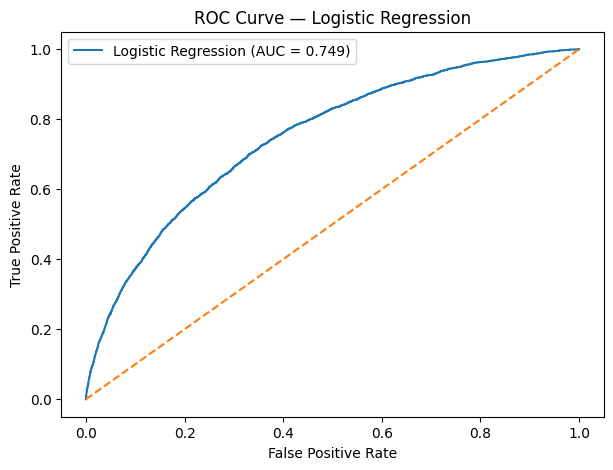

In [ ]:
from sklearn.metrics import roc_curve, precision_recall_curve

# ROC curve
fpr, tpr, _ = roc_curve(y_val, y_val_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Logistic Regression")
plt.legend()
plt.show()

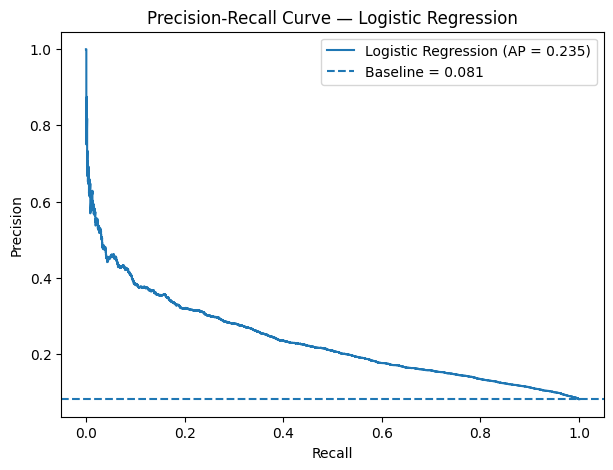

In [ ]:
# Precision-Recall curve
precision, recall, _ = precision_recall_curve(y_val, y_val_prob)

plt.figure(figsize=(7, 5))
plt.plot(recall, precision, label=f"Logistic Regression (AP = {pr_auc:.3f})")
plt.axhline(
    y=y_val.mean(),
    linestyle="--",
    label=f"Baseline = {y_val.mean():.3f}"
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve — Logistic Regression")
plt.legend()
plt.show()

In [ ]:
y_val_pred_05 = (y_val_prob >= 0.50).astype(int)

In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

cm = confusion_matrix(y_val, y_val_pred_05)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_05, digits=4))

Confusion Matrix:
[[42367    36]
 [ 3673    51]]

Classification Report:
              precision    recall  f1-score   support

           0     0.9202    0.9992    0.9581     42403
           1     0.5862    0.0137    0.0268      3724

    accuracy                         0.9196     46127
   macro avg     0.7532    0.5064    0.4924     46127
weighted avg     0.8933    0.9196    0.8829     46127



In [ ]:
accuracy = accuracy_score(y_val, y_val_pred_05)
precision = precision_score(y_val, y_val_pred_05)
recall = recall_score(y_val, y_val_pred_05)
f1 = f1_score(y_val, y_val_pred_05)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

Accuracy:  0.9196
Precision: 0.5862
Recall:    0.0137
F1 Score:  0.0268


### Baseline Model Results

The logistic regression baseline achieved a validation ROC-AUC of **0.7495** and
a PR-AUC of **0.2348**, compared with a positive-class prevalence of **0.0807**.
These results indicate that the model has meaningful ability to rank applicants
by repayment risk, with the PR-AUC substantially exceeding the performance
expected from a random ranking.

However, using the default classification threshold of 0.50 produced an
accuracy of **91.96%**, precision of **58.62%**, recall of only **1.37%**, and an
F1 score of **0.0268**. The high accuracy is misleading because approximately
91.9% of applicants belong to the negative class. At this threshold, the model
correctly identified only **51 of 3,724** applicants who experienced repayment
difficulty, while missing **3,673** positive cases.

These results suggest that the logistic regression model has useful
discriminative ability, but the default 0.50 classification threshold is poorly
suited to the imbalanced target. Further analysis should therefore evaluate the
precision-recall tradeoff across alternative thresholds rather than relying on
accuracy or the default cutoff alone.

## Classification Threshold Analysis

The default 0.50 classification threshold results in extremely low recall for
the positive class. Because the model is intended to rank and identify
higher-risk applicants, alternative thresholds are evaluated to understand
the tradeoff between precision and recall.

In [ ]:
pd.Series(y_val_prob).describe(
    percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
)

,0
count,46127.000000
mean,0.080927
std,0.076950
min,0.000008
50%,0.055788
75%,0.103916
90%,0.178798
95%,0.238497
99%,0.376933
max,0.734909


In [ ]:
print("Maximum predicted probability:", y_val_prob.max())
print("Applicants predicted >= 0.50:", (y_val_prob >= 0.50).sum())

Maximum predicted probability: 0.7349090534720779
Applicants predicted >= 0.50: 87


The predicted probabilities are concentrated well below the default 0.50
classification threshold. The median predicted probability is approximately
5.6%, while the 90th, 95th, and 99th percentiles are approximately 17.9%,
23.8%, and 37.7%, respectively. Only 87 of 46,127 validation applicants
received a predicted probability of at least 50%.

This distribution helps explain the extremely low recall observed at the 0.50
threshold. Although the model demonstrates useful ranking ability based on its
ROC-AUC of 0.7495, the default threshold classifies almost every applicant as
negative. Therefore, lower decision thresholds should be evaluated to identify
a more appropriate tradeoff between precision and recall.

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.05, 0.075, 0.10, 0.125, 0.15,
              0.20, 0.25, 0.30, 0.40, 0.50]

threshold_results = []

for threshold in thresholds:
    y_pred = (y_val_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Predicted Positive": y_pred.sum(),
        "Precision": precision_score(y_val, y_pred),
        "Recall": recall_score(y_val, y_pred),
        "F1": f1_score(y_val, y_pred)
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df

,Threshold,Predicted Positive,Precision,Recall,F1
0,0.050,25255,0.124015,0.841031,0.216157
1,0.075,17339,0.153181,0.713212,0.252196
2,0.100,12142,0.180119,0.587272,0.275684
3,0.125,8765,0.209812,0.493824,0.294499
4,0.150,6365,0.234407,0.400644,0.295768
5,0.200,3562,0.288602,0.276047,0.282185
6,0.250,2063,0.329132,0.182331,0.234664
7,0.300,1200,0.374167,0.120569,0.182372
8,0.400,348,0.454023,0.042427,0.077603
9,0.500,87,0.586207,0.013695,0.026765


Changing the classification threshold demonstrates the tradeoff between
precision and recall. Lower thresholds identify a much larger proportion of
applicants who experience repayment difficulty, but also produce more false
positive classifications.

At the default threshold of 0.50, precision is relatively high at 58.6%, but
recall is only 1.4%, meaning that nearly all positive cases are missed.
Reducing the threshold substantially improves recall. For example, a threshold
of 0.15 achieves 23.4% precision and 40.1% recall, with an F1 score of 0.296,
the highest among the thresholds evaluated.

These results demonstrate that the default 0.50 threshold is not appropriate
for this imbalanced credit-risk problem. The final operating threshold should
depend on the relative costs of false positives and false negatives rather
than being selected solely from the default cutoff or a single classification
metric.

## LightGBM Model

A LightGBM gradient-boosted tree model is trained to determine whether nonlinear
relationships and feature interactions improve upon the logistic regression
baseline.

Unlike logistic regression, gradient-boosted decision trees do not assume a
linear relationship between the predictors and the log-odds of repayment
difficulty. This allows the model to capture more complex patterns in applicant
characteristics.

Model performance is evaluated on the validation set using the same ROC-AUC and
PR-AUC metrics used for the logistic regression baseline.

In [ ]:
from lightgbm import LGBMClassifier

In [ ]:
lgbm = LGBMClassifier(
    objective="binary",
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    n_jobs=-1
)

lgbm.fit(X_train, y_train)

[LightGBM] [Info] Number of positive: 17377, number of negative: 197880
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.244605 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 12245
[LightGBM] [Info] Number of data points in the train set: 215257, number of used features: 301
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080727 -> initscore=-2.432513
[LightGBM] [Info] Start training from score -2.432513


LGBMClassifier(learning_rate=0.05, n_estimators=500, n_jobs=-1,
               objective='binary', random_state=42)

In [ ]:
y_val_prob_lgbm = lgbm.predict_proba(X_val)[:, 1]

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [ ]:
lgbm_roc_auc = roc_auc_score(
    y_val,
    y_val_prob_lgbm
)

lgbm_pr_auc = average_precision_score(
    y_val,
    y_val_prob_lgbm
)

print(f"LightGBM Validation ROC-AUC: {lgbm_roc_auc:.4f}")
print(f"LightGBM Validation PR-AUC:  {lgbm_pr_auc:.4f}")

LightGBM Validation ROC-AUC: 0.7644
LightGBM Validation PR-AUC:  0.2547


In [ ]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "LightGBM"
    ],
    "ROC-AUC": [
        roc_auc,
        lgbm_roc_auc
    ],
    "PR-AUC": [
        pr_auc,
        lgbm_pr_auc
    ]
})

model_comparison

,Model,ROC-AUC,PR-AUC
0,Logistic Regression,0.749477,0.234839
1,LightGBM,0.764387,0.254712


### Initial Model Comparison

LightGBM outperformed the logistic regression baseline on both validation
metrics. ROC-AUC increased from **0.7495 to 0.7644**, while PR-AUC increased
from **0.2348 to 0.2547**.

The improvement suggests that nonlinear relationships and interactions among
applicant characteristics contain predictive information that is not fully
captured by the logistic regression model. LightGBM therefore provides the
stronger initial model for ranking applicants by repayment risk.

However, these results are based on an initial set of LightGBM
hyperparameters. Further tuning will be performed using the validation set
before selecting the final model.

## LightGBM Hyperparameter Tuning

The initial LightGBM model outperformed the logistic regression baseline.
A small set of alternative hyperparameter configurations is evaluated to
determine whether model performance can be improved while controlling model
complexity.

Each configuration is trained using the same training data and evaluated on
the validation set using ROC-AUC and PR-AUC. The test set remains untouched
during model selection.

In [ ]:
lgbm_configs = [
    {
        "name": "Baseline",
        "num_leaves": 31,
        "max_depth": -1,
        "min_child_samples": 20,
        "subsample": 1.0,
        "colsample_bytree": 1.0,
        "reg_lambda": 0.0
    },
    {
        "name": "Smaller Trees",
        "num_leaves": 15,
        "max_depth": 5,
        "min_child_samples": 30,
        "subsample": 0.9,
        "colsample_bytree": 0.9,
        "reg_lambda": 1.0
    },
    {
        "name": "Moderate Regularization",
        "num_leaves": 31,
        "max_depth": 7,
        "min_child_samples": 40,
        "subsample": 0.9,
        "colsample_bytree": 0.9,
        "reg_lambda": 1.0
    },
    {
        "name": "Larger Trees",
        "num_leaves": 63,
        "max_depth": -1,
        "min_child_samples": 30,
        "subsample": 0.9,
        "colsample_bytree": 0.9,
        "reg_lambda": 1.0
    },
    {
        "name": "Strong Regularization",
        "num_leaves": 31,
        "max_depth": 6,
        "min_child_samples": 60,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "reg_lambda": 5.0
    }
]

In [ ]:
tuning_results = []
trained_models = {}

for config in lgbm_configs:

    name = config["name"]

    params = {
        key: value
        for key, value in config.items()
        if key != "name"
    }

    model = LGBMClassifier(
        objective="binary",
        n_estimators=500,
        learning_rate=0.05,
        random_state=42,
        n_jobs=-1,
        verbosity=-1,
        **params
    )

    model.fit(X_train, y_train)

    val_prob = model.predict_proba(X_val)[:, 1]

    roc = roc_auc_score(y_val, val_prob)
    pr = average_precision_score(y_val, val_prob)

    tuning_results.append({
        "Model": name,
        "ROC-AUC": roc,
        "PR-AUC": pr
    })

    trained_models[name] = model

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [ ]:
tuning_df = pd.DataFrame(tuning_results)

tuning_df = tuning_df.sort_values(
    "ROC-AUC",
    ascending=False
).reset_index(drop=True)

tuning_df

,Model,ROC-AUC,PR-AUC
0,Strong Regularization,0.766670,0.255944
1,Smaller Trees,0.766329,0.255266
2,Moderate Regularization,0.766092,0.256134
3,Baseline,0.764387,0.254712
4,Larger Trees,0.763682,0.253916


### LightGBM Tuning Results

Regularized LightGBM configurations slightly improved upon the initial
baseline model. The Strong Regularization configuration achieved the highest
validation ROC-AUC of **0.7667**, compared with **0.7644** for the baseline,
while the Moderate Regularization configuration achieved the highest PR-AUC
of **0.2561**.

The differences among the best configurations were small, indicating that
LightGBM performance was relatively stable across reasonable parameter
settings. Increasing tree complexity did not improve performance, as the
Larger Trees configuration produced the lowest ROC-AUC and PR-AUC among the
tested models.

The Strong Regularization configuration was selected as the current candidate
model because it achieved the highest validation ROC-AUC while maintaining
competitive PR-AUC performance.

In [ ]:
best_lgbm = trained_models["Strong Regularization"]

y_val_prob_best = best_lgbm.predict_proba(X_val)[:, 1]

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


## Probability Calibration

Discrimination metrics such as ROC-AUC measure how effectively the model ranks
higher-risk applicants above lower-risk applicants, but they do not determine
whether the predicted probabilities accurately represent observed risk.

Because the objective of this project is probability-of-default estimation,
the calibration of predicted probabilities is also evaluated. A well-calibrated
model should produce predicted probabilities that correspond closely to
observed repayment-difficulty rates.

In [ ]:
from sklearn.metrics import brier_score_loss

log_brier = brier_score_loss(y_val, y_val_prob)
lgbm_brier = brier_score_loss(y_val, y_val_prob_best)

print(f"Logistic Regression Brier Score: {log_brier:.4f}")
print(f"LightGBM Brier Score:             {lgbm_brier:.4f}")

Logistic Regression Brier Score: 0.0683
LightGBM Brier Score:             0.0673


## XGBoost Model

XGBoost is evaluated as an additional gradient-boosted tree model and compared
with logistic regression and LightGBM.

Like LightGBM, XGBoost can capture nonlinear relationships and interactions
between applicant characteristics. Model performance is evaluated using the
same validation ROC-AUC and PR-AUC metrics to ensure a consistent comparison
across model families.

In [ ]:
from xgboost import XGBClassifier

In [ ]:
xgb_model = XGBClassifier(
    objective="binary:logistic",
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    min_child_weight=1,
    subsample=0.9,
    colsample_bytree=0.9,
    reg_lambda=1.0,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.9, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=1, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=500, n_jobs=-1,
              num_parallel_tree=None, ...)

In [ ]:
y_val_prob_xgb = xgb_model.predict_proba(X_val)[:, 1]

In [ ]:
xgb_roc_auc = roc_auc_score(
    y_val,
    y_val_prob_xgb
)

xgb_pr_auc = average_precision_score(
    y_val,
    y_val_prob_xgb
)

print(f"XGBoost Validation ROC-AUC: {xgb_roc_auc:.4f}")
print(f"XGBoost Validation PR-AUC:  {xgb_pr_auc:.4f}")

XGBoost Validation ROC-AUC: 0.7653
XGBoost Validation PR-AUC:  0.2555


In [ ]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "LightGBM Baseline",
        "LightGBM Tuned",
        "XGBoost Baseline"
    ],
    "ROC-AUC": [
        roc_auc,
        lgbm_roc_auc,
        roc_auc_score(y_val, y_val_prob_best),
        xgb_roc_auc
    ],
    "PR-AUC": [
        pr_auc,
        lgbm_pr_auc,
        average_precision_score(y_val, y_val_prob_best),
        xgb_pr_auc
    ]
})

model_comparison.sort_values(
    "ROC-AUC",
    ascending=False
).reset_index(drop=True)

,Model,ROC-AUC,PR-AUC
0,LightGBM Tuned,0.766670,0.255944
1,XGBoost Baseline,0.765307,0.255502
2,LightGBM Baseline,0.764387,0.254712
3,Logistic Regression,0.749477,0.234839


### XGBoost Results

The baseline XGBoost model achieved a validation ROC-AUC of **0.7653** and
PR-AUC of **0.2555**, substantially outperforming logistic regression and
performing similarly to LightGBM.

The tuned LightGBM model remains the strongest model, with a ROC-AUC of
**0.7667** and PR-AUC of **0.2559**. However, the performance difference
between tuned LightGBM and baseline XGBoost is small, suggesting that both
gradient-boosting approaches are strong candidates for the final model.

Because the XGBoost results were obtained before hyperparameter tuning,
additional tuning may determine whether XGBoost can match or outperform the
current LightGBM model.

## Random Forest Model

Random Forest is evaluated as a bagging-based ensemble model to provide an
additional comparison with logistic regression and gradient-boosting methods.

Unlike LightGBM and XGBoost, which sequentially construct trees to correct
previous prediction errors, Random Forest trains many decision trees using
different bootstrap samples and subsets of features and aggregates their
predictions.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=30,
    max_features="sqrt",
    random_state=42,
    n_jobs=2
)

rf_model.fit(X_train, y_train)

RandomForestClassifier(max_depth=10, min_samples_leaf=30, n_estimators=200,
                       n_jobs=2, random_state=42)

In [ ]:
y_val_prob_rf = rf_model.predict_proba(X_val)[:, 1]

In [ ]:
rf_roc_auc = roc_auc_score(
    y_val,
    y_val_prob_rf
)

rf_pr_auc = average_precision_score(
    y_val,
    y_val_prob_rf
)

print(f"Random Forest Validation ROC-AUC: {rf_roc_auc:.4f}")
print(f"Random Forest Validation PR-AUC:  {rf_pr_auc:.4f}")

Random Forest Validation ROC-AUC: 0.7380
Random Forest Validation PR-AUC:  0.2249


### Random Forest Results

The Random Forest model achieved a validation ROC-AUC of **0.7380** and
PR-AUC of **0.2249**, underperforming logistic regression as well as both
gradient-boosting models.

Although Random Forest can capture nonlinear relationships and feature
interactions, its bagging-based approach was less effective for this dataset
than the sequential boosting strategies used by LightGBM and XGBoost.

These results provide additional evidence that gradient boosting is the
strongest modeling approach among the model families evaluated. Random Forest
will therefore not be prioritized for additional hyperparameter tuning.

## XGBoost Hyperparameter Tuning

The baseline XGBoost model performed similarly to the tuned LightGBM model,
making it a strong candidate for further optimization.

Several XGBoost configurations are evaluated to examine the effects of tree
complexity, minimum child weight, row and feature sampling, and regularization.
Each model is evaluated on the validation set using ROC-AUC and PR-AUC, while
the test set remains untouched.

In [ ]:
xgb_configs = [
    {
        "name": "Baseline",
        "max_depth": 6,
        "min_child_weight": 1,
        "subsample": 0.9,
        "colsample_bytree": 0.9,
        "reg_lambda": 1.0,
        "reg_alpha": 0.0
    },
    {
        "name": "Shallow Trees",
        "max_depth": 4,
        "min_child_weight": 5,
        "subsample": 0.9,
        "colsample_bytree": 0.9,
        "reg_lambda": 1.0,
        "reg_alpha": 0.0
    },
    {
        "name": "Moderate Regularization",
        "max_depth": 5,
        "min_child_weight": 5,
        "subsample": 0.9,
        "colsample_bytree": 0.9,
        "reg_lambda": 5.0,
        "reg_alpha": 0.1
    },
    {
        "name": "Strong Regularization",
        "max_depth": 4,
        "min_child_weight": 10,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "reg_lambda": 10.0,
        "reg_alpha": 0.5
    },
    {
        "name": "Deeper Trees",
        "max_depth": 8,
        "min_child_weight": 5,
        "subsample": 0.9,
        "colsample_bytree": 0.9,
        "reg_lambda": 1.0,
        "reg_alpha": 0.0
    }
]

In [ ]:
xgb_tuning_results = []
trained_xgb_models = {}

for config in xgb_configs:

    name = config["name"]

    params = {
        key: value
        for key, value in config.items()
        if key != "name"
    }

    model = XGBClassifier(
        objective="binary:logistic",
        n_estimators=500,
        learning_rate=0.05,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1,
        **params
    )

    model.fit(X_train, y_train)

    val_prob = model.predict_proba(X_val)[:, 1]

    roc = roc_auc_score(y_val, val_prob)
    pr = average_precision_score(y_val, val_prob)

    xgb_tuning_results.append({
        "Model": name,
        "ROC-AUC": roc,
        "PR-AUC": pr
    })

    trained_xgb_models[name] = model

In [ ]:
xgb_tuning_df = pd.DataFrame(xgb_tuning_results)

xgb_tuning_df = xgb_tuning_df.sort_values(
    "ROC-AUC",
    ascending=False
).reset_index(drop=True)

xgb_tuning_df

### XGBoost Tuning and Model Selection

Hyperparameter tuning improved XGBoost's validation ROC-AUC from 0.7653
to 0.7661 and PR-AUC from 0.2555 to 0.2566. The Shallow Trees
configuration achieved the strongest overall results, while deeper
trees performed worse, suggesting that controlling model complexity
is beneficial.

Comparing the strongest models, tuned LightGBM achieved the highest
ROC-AUC (0.7667), while tuned XGBoost achieved the highest PR-AUC
(0.2566). The differences were small, indicating that both models
provide similar predictive performance.

LightGBM was selected as the primary candidate for subsequent
probability calibration, explainability, and decision-threshold
analysis. XGBoost will be retained as a competitive alternative.
The final test dataset remains untouched.

In [ ]:
best_lgbm = trained_models["Strong Regularization"]
best_xgb = trained_xgb_models["Shallow Trees"]

joblib.dump(
    best_lgbm,
    MODEL_PATH / "lightgbm_tuned.joblib"
)

joblib.dump(
    best_xgb,
    MODEL_PATH / "xgboost_tuned.joblib"
)

joblib.dump(
    log_reg,
    MODEL_PATH / "logistic_regression.joblib"
)

print("Models saved successfully!")

### Probability Calibration

Probability calibration evaluates whether predicted default probabilities
correspond to observed default frequencies.

Although ROC-AUC and PR-AUC measure a model's ability to distinguish
between classes, they do not directly assess probability accuracy.

Calibration curves and Brier scores are used to evaluate the
probability estimates of Logistic Regression, LightGBM, and XGBoost
on the validation dataset.

In [ ]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

# Validation probabilities
model_probs = {
    "Logistic Regression": log_reg.predict_proba(X_val)[:, 1],
    "LightGBM": best_lgbm.predict_proba(X_val)[:, 1],
    "XGBoost": best_xgb.predict_proba(X_val)[:, 1]
}

plt.figure(figsize=(8, 6))

# Perfect calibration reference
plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="black",
    label="Perfect Calibration"
)

for name, probs in model_probs.items():

    fraction_positive, mean_predicted = calibration_curve(
        y_val,
        probs,
        n_bins=10,
        strategy="quantile"
    )

    brier = brier_score_loss(y_val, probs)

    plt.plot(
        mean_predicted,
        fraction_positive,
        marker="o",
        label=f"{name} (Brier={brier:.4f})"
    )

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Default Rate")
plt.title("Validation Calibration Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
plt.figure(figsize=(8, 6))

plt.plot(
    [0, 0.35], [0, 0.35],
    linestyle="--",
    color="black",
    label="Perfect Calibration"
)

for name, probs in model_probs.items():

    fraction_positive, mean_predicted = calibration_curve(
        y_val,
        probs,
        n_bins=10,
        strategy="quantile"
    )

    plt.plot(
        mean_predicted,
        fraction_positive,
        marker="o",
        label=name
    )

plt.xlim(0, 0.35)
plt.ylim(0, 0.35)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Default Rate")
plt.title("Validation Calibration Curves (Zoomed)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()